# E2 · Fine-tuning parcial: MobileNetV2 desde E1, último bloque descongelado

**Pregunta del experimento:** ¿mejora frente a E1 y a qué costo?

**Condiciones del taller y del protocolo:**
- Mismo backbone A (MobileNetV2) y **parte del modelo E1 ya entrenado** (`checkpoints/E1.pt`, mejor época de las 10)
- Se descongela **el último bloque**: `features[-2:]` = último bloque residual invertido + convolución final
- La cabeza lineal también sigue entrenándose
- **LR menor**: 0,0001 (diez veces menor que E1) · **2 épocas adicionales** (decisiones 7 y 8)
- Batch 32 · semilla 42 · sin tratamiento del desbalance · se guarda la mejor época según macro-F1 en validación

**Comparación válida:** E2 frente a E1 (efecto del fine-tuning). **No** se compara E2 con E3.

**Antes de ejecutar:** GPU T4 y acceso al secreto `GH_TOKEN` activados.

## Celda 1 · Configuración de la sesión
**Cambia tu nombre y el correo de tu cuenta de GitHub.**

In [1]:
from google.colab import drive, userdata
drive.mount('/content/drive')

token = userdata.get('GH_TOKEN')
![ -d /content/yuca_transfer ] || git clone https://{token}@github.com/Frank-Dev007/yuca_transfer.git /content/yuca_transfer
%cd /content/yuca_transfer
!git pull
!git config user.name "GhostnzaDevz64"
!git config user.email "tomasgonzalezlopez06@gmail.com"

!python scripts/preparar_datos.py
!nvidia-smi --query-gpu=name,memory.total --format=csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/yuca_transfer
Already up to date.
Tamaño del zip (MB): 1354.1
Contenido de data/: ['cassavaleafdata', 'cassavaleafdata.zip']
name, memory.total [MiB]
Tesla T4, 15360 MiB


## Celda 2 · Verificar el punto de partida
E2 debe partir de **E1 completo (10 épocas)**. Si aquí aparece `épocas: 1`, los nombres de E1 y E1_prueba están al revés: corríjanlos antes de seguir.

In [2]:
import json
m_e1 = json.load(open("results/E1/metricas.json"))
print(f"E1 · épocas: {m_e1['epocas']} | mejor época: {m_e1['mejor_epoca']} | "
      f"macro-F1 val: {m_e1['validacion']['macro_f1']:.4f} | macro-F1 test: {m_e1['test']['macro_f1']:.4f}")
assert m_e1["epocas"] == 10, "checkpoints/E1.pt no es E1 completo: revisar nombres antes de seguir"

E1 · épocas: 10 | mejor época: 9 | macro-F1 val: 0.7040 | macro-F1 test: 0.6944


## Celda 3 · Preparar

In [3]:
import sys, torch
sys.path.append("/content/yuca_transfer")
from src.utils import fijar_semilla, obtener_dispositivo
from src.data import crear_dataloaders
from src.models import crear_modelo, descongelar_ultimo_bloque
from src.train import ejecutar_experimento

SEED, BATCH = 42, 32
LR_E2, EPOCAS_E2 = 0.0001, 2      # protocolo: decisiones 7 y 8
fijar_semilla(SEED)
dispositivo = obtener_dispositivo()
loaders = crear_dataloaders(batch_size=BATCH, seed=SEED)
print(dispositivo, {s: len(l.dataset) for s, l in loaders.items()})

cuda {'train': 5616, 'validation': 1878, 'test': 1874}


## Celda 4 · Cargar E1 y descongelar el último bloque
- `load_state_dict` carga los pesos de E1 (backbone de ImageNet + cabeza ya entrenada).
- `descongelar_ultimo_bloque` pone `requires_grad = True` solo en `features[-2:]`.

✅ Los parámetros entrenables deben **subir** respecto a E1 (6.405). Esa diferencia es parte del costo de E2.

In [4]:
fijar_semilla(SEED)
modelo = crear_modelo("mobilenet_v2")
modelo.load_state_dict(torch.load("checkpoints/E1.pt", map_location=dispositivo))   # punto de partida: E1

antes = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
modelo = descongelar_ultimo_bloque(modelo, "mobilenet_v2")
despues = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
total = sum(p.numel() for p in modelo.parameters())

print(f"Entrenables antes (E1): {antes:,}")
print(f"Entrenables ahora (E2): {despues:,} de {total:,} ({despues / total:.1%} del modelo)")
print("Bloques entrenables:", [i for i, b in enumerate(modelo.features)
                               if any(p.requires_grad for p in b.parameters())], "+ cabeza")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 83.8MB/s]


Entrenables antes (E1): 6,405
Entrenables ahora (E2): 892,485 de 2,230,277 (40.0% del modelo)
Bloques entrenables: [17, 18] + cabeza


## Celda 5 · Entrenar E2 (2 épocas, LR 0,0001)
Usa la misma función `ejecutar_experimento` que E1: mismas métricas, mismos archivos de salida.

Época  1 | pérdida train 0.6769 | pérdida val 0.6099 | macro-F1 val 0.7053 | 60 s
Época  2 | pérdida train 0.4571 | pérdida val 0.5676 | macro-F1 val 0.7264 | 117 s


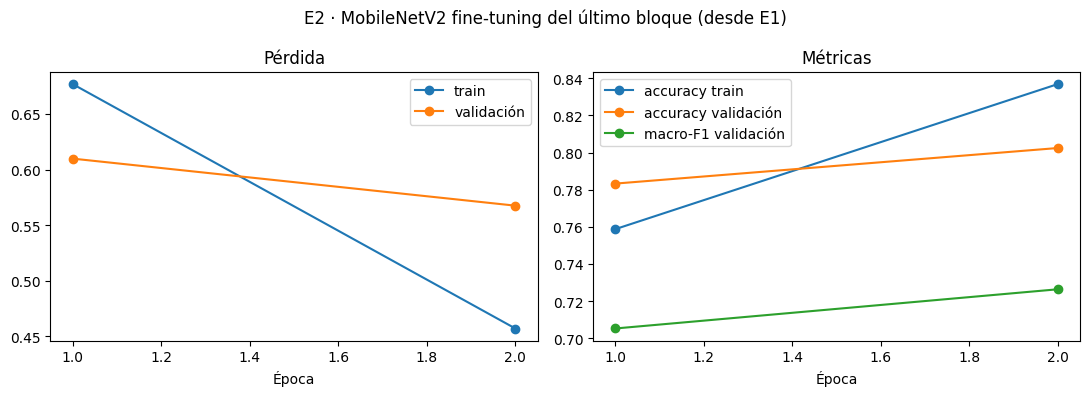

Validación (mejor época): accuracy = 0.8024 | macro-F1 = 0.7264
   cbb      recall = 0.510   F1 = 0.552   (n = 151)
   cbsd     recall = 0.781   F1 = 0.776   (n = 479)
   cgm      recall = 0.751   F1 = 0.730   (n = 257)
   cmd      recall = 0.896   F1 = 0.891   (n = 886)
   healthy  recall = 0.657   F1 = 0.683   (n = 105)

Test: accuracy = 0.8042 | macro-F1 = 0.7323
   cbb      recall = 0.506   F1 = 0.523   (n = 154)
   cbsd     recall = 0.778   F1 = 0.775   (n = 477)
   cgm      recall = 0.739   F1 = 0.735   (n = 253)
   cmd      recall = 0.903   F1 = 0.894   (n = 885)
   healthy  recall = 0.686   F1 = 0.735   (n = 105)


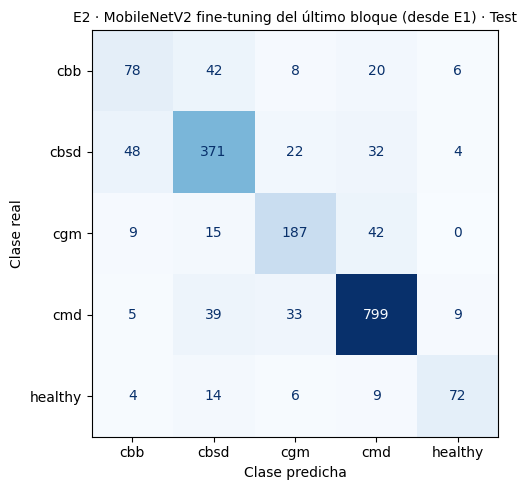


Mejor época: 2 | entrenamiento: 117 s | inferencia: 1.23 ms/imagen | parámetros entrenables: 892,485


In [5]:
r_e2 = ejecutar_experimento("E2", modelo, loaders, dispositivo, epocas=EPOCAS_E2, lr=LR_E2, semilla=SEED,
                            descripcion="MobileNetV2 fine-tuning del último bloque (desde E1)",
                            extra={"parte_de": "checkpoints/E1.pt",
                                   "bloques_descongelados": "features[-2:] + cabeza"})

## Celda 6 · Comparación E1 frente a E2 (hechos, sin interpretar)
El costo de E2 se reporta como **E1 + E2** (protocolo, decisión 7).

In [6]:
import pandas as pd
m_e2 = json.load(open("results/E2/metricas.json"))
tabla = pd.DataFrame([
    {"Experimento": "E1", "Accuracy test": m_e1["test"]["accuracy"], "Macro-F1 test": m_e1["test"]["macro_f1"],
     "Entrenamiento (s)": m_e1["tiempo_entrenamiento_s"], "Parámetros entrenables": m_e1["parametros_entrenables"],
     "Inferencia (ms/img)": m_e1["tiempo_inferencia_ms_por_imagen"]},
    {"Experimento": "E2 (desde E1)", "Accuracy test": m_e2["test"]["accuracy"], "Macro-F1 test": m_e2["test"]["macro_f1"],
     "Entrenamiento (s)": m_e1["tiempo_entrenamiento_s"] + m_e2["tiempo_entrenamiento_s"],
     "Parámetros entrenables": m_e2["parametros_entrenables"],
     "Inferencia (ms/img)": m_e2["tiempo_inferencia_ms_por_imagen"]},
]).round(4)
print("Entrenamiento de E2 = tiempo de E1 + tiempo de las 2 épocas adicionales")
print(f"Solo las 2 épocas de E2: {m_e2['tiempo_entrenamiento_s']:.0f} s | mejor época de E2: {m_e2['mejor_epoca']}")

recall = pd.DataFrame({"E1": {c: v["recall"] for c, v in m_e1["test"]["por_clase"].items()},
                       "E2": {c: v["recall"] for c, v in m_e2["test"]["por_clase"].items()}}).round(3)
recall["diferencia"] = (recall.E2 - recall.E1).round(3)
display(tabla)
print("\nRecall por clase en test:")
display(recall)
tabla.to_csv("results/E2/comparacion_E1_E2.csv", index=False)

Entrenamiento de E2 = tiempo de E1 + tiempo de las 2 épocas adicionales
Solo las 2 épocas de E2: 117 s | mejor época de E2: 2


,Experimento,Accuracy test,Macro-F1 test,Entrenamiento (s),Parámetros entrenables,Inferencia (ms/img)
0,E1,0.7689,0.6944,524.0918,6405,1.1450
1,E2 (desde E1),0.8042,0.7323,641.2966,892485,1.2292



Recall por clase en test:


,E1,E2,diferencia
cbb,0.539,0.506,-0.033
cbsd,0.795,0.778,-0.017
cgm,0.723,0.739,0.016
cmd,0.832,0.903,0.071
healthy,0.571,0.686,0.115


## Celda 7 · Subir resultados

In [7]:
!git pull
!git add results/E2 checkpoints/E2.pt
!git commit -m "E2: fine-tuning del último bloque de MobileNetV2 desde E1 (2 épocas, LR 0.0001)"
!git push

Already up to date.
[main 1453106] E2: fine-tuning del último bloque de MobileNetV2 desde E1 (2 épocas, LR 0.0001)
 7 files changed, 1971 insertions(+)
 create mode 100644 checkpoints/E2.pt
 create mode 100644 results/E2/comparacion_E1_E2.csv
 create mode 100644 results/E2/curvas.png
 create mode 100644 results/E2/historial.csv
 create mode 100644 results/E2/matriz_confusion_test.png
 create mode 100644 results/E2/metricas.json
 create mode 100644 results/E2/predicciones_test.csv
Enumerating objects: 15, done.
Counting objects: 100% (15/15), done.
Delta compression using up to 2 threads
Compressing objects: 100% (12/12), done.
Writing objects: 100% (12/12), 8.16 MiB | 9.66 MiB/s, done.
Total 12 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/Frank-Dev007/yuca_transfer.git
   f4b9773..1453106  main -> main


## Celda 8 · Subir este notebook
1. **Archivo → Guardar una copia en Drive**.
2. Mira el nombre exacto con `!ls "/content/drive/MyDrive/Colab Notebooks/"` y reemplaza `NOMBRE_EXACTO`.

In [ ]:
%cd /content/yuca_transfer
!cp "/content/drive/MyDrive/Colab Notebooks/NOMBRE_EXACTO.ipynb" notebooks/04_E2_finetuning.ipynb
!git add notebooks/04_E2_finetuning.ipynb
!git commit -m "Notebook E2"
!git push